# Bike sharing: hourly demand forecasting

**Question:** How accurately can an operator forecast the next hour's total rental demand?

Dataset: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset). The evaluation holds out the final 20% of time, which better reflects real forecasting than a random split.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = Path('../datasets/bike-sharing/hour.csv')
df = pd.read_csv(DATA_PATH)
df['timestamp'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')
df = df.sort_values('timestamp').reset_index(drop=True)
display(df.head())
print(df[['cnt', 'casual', 'registered']].describe())

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


                cnt        casual    registered
count  17379.000000  17379.000000  17379.000000
mean     189.463088     35.676218    153.786869
std      181.387599     49.305030    151.357286
min        1.000000      0.000000      0.000000
25%       40.000000      4.000000     34.000000
50%      142.000000     17.000000    115.000000
75%      281.000000     48.000000    220.000000
max      977.000000    367.000000    886.000000


## Feature policy

`casual` and `registered` sum to the target `cnt`, so they are excluded as direct leakage. `instant` and raw date strings are also excluded; calendar and weather signals are already supplied in usable form.

In [ ]:
target = 'cnt'
leakage_or_id = ['cnt', 'casual', 'registered', 'instant', 'dteday', 'timestamp']
features = [column for column in df.columns if column not in leakage_or_id]

cutoff = int(len(df) * 0.80)
train, test = df.iloc[:cutoff], df.iloc[cutoff:]
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print(f'Train ends: {train.timestamp.max()}')
print(f'Test begins: {test.timestamp.min()}')

model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0, random_state=42)
model.fit(X_train, y_train)
prediction = np.clip(model.predict(X_test), 0, None)

Train ends: 2012-08-07 11:00:00
Test begins: 2012-08-07 12:00:00


Historical mean    MAE= 174.98 | RMSE=54106.66
Gradient boosting  MAE=  40.25 | RMSE=3887.14
Gradient boosting R²: 0.92


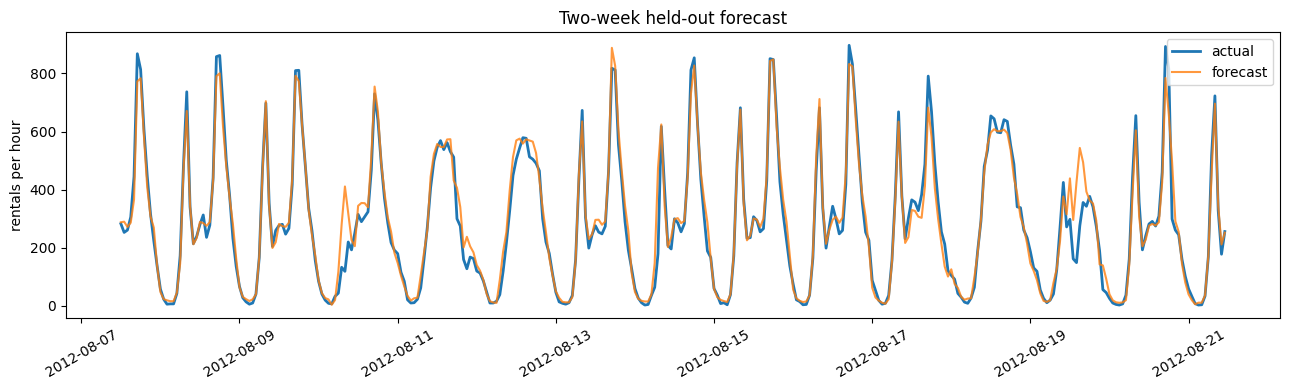

In [ ]:

baseline = np.repeat(y_train.mean(), len(y_test))
for name, values in [('Historical mean', baseline), ('Gradient boosting', prediction)]:
    mae = mean_absolute_error(y_test, values)
    rmse = mean_squared_error(y_test, values)
    print(f'{name:18} MAE={mae:7.2f} | RMSE={rmse:7.2f}')
print('Gradient boosting R²:', round(r2_score(y_test, prediction), 3))

window = 24 * 14
plt.figure(figsize=(13, 4))
plt.plot(test.timestamp.iloc[:window], y_test.iloc[:window], label='actual', linewidth=2)
plt.plot(test.timestamp.iloc[:window], prediction[:window], label='forecast', alpha=0.8)
plt.xticks(rotation=30); plt.ylabel('rentals per hour'); plt.title('Two-week held-out forecast'); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:

evaluation = test[['hr', 'weathersit', 'workingday']].copy()
evaluation['absolute_error'] = np.abs(y_test.to_numpy() - prediction)
display(evaluation.groupby('hr')['absolute_error'].agg(['mean', 'median', 'count']).round(1))

,mean,median,count
hr,,,
0,18.0,12.0,145
1,14.1,9.3,144
2,11.2,8.3,144
3,8.5,7.1,141
4,6.0,5.4,143
5,9.9,8.6,144
6,18.0,12.1,144
7,64.7,54.7,144
8,86.1,65.8,144


## Conclusion and limitations

This is a strong non-linear baseline. Production work should use future weather forecasts rather than observed weather, introduce lagged-demand features available at prediction time, backtest across multiple rolling windows, and attach prediction intervals for staffing decisions.